<a href="https://colab.research.google.com/github/lakaderohan16-del/district-development-index/blob/main/notebooks/01_district_development_index.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
base = '/content/drive/MyDrive/district-development-index'
for f in ['data/raw', 'data/clean', 'sql', 'notebooks', 'dashboard', 'brief']:
    os.makedirs(f"{base}/{f}", exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import pandas as pd
url = "https://raw.githubusercontent.com/SaiSiddhardhaKalla/NFHS/main/India.csv"
df = pd.read_csv(url)
df.to_csv(f"{base}/data/raw/nfhs5_india.csv", index=False)
df.head()

/tmp/ipykernel_12933/193567601.py:3: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


,State,ST_CEN_CD,District,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Female population age 6 years and above who ev...,78.0,77.2
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Population below age 15 years (%),23.0,25.4
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Sex ratio of the total population (females per...,973.0,957.0
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Sex ratio at birth for children born in the la...,927.0,1060.0
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Children under age 5 years whose birth was reg...,98.0,99.3


In [5]:
print(df.shape)
print(df.columns.tolist()[:15])
df.head(10)

(73632, 9)
['State', 'ST_CEN_CD', 'District', 'DISTRICT', 'DT_CEN_CD', 'Category', 'Indicator', 'NFHS 5', 'NFHS 4']


,State,ST_CEN_CD,District,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Female population age 6 years and above who ev...,78.0,77.2
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Population below age 15 years (%),23.0,25.4
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Sex ratio of the total population (females per...,973.0,957.0
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Sex ratio at birth for children born in the la...,927.0,1060.0
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Children under age 5 years whose birth was reg...,98.0,99.3
5,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Deaths in the last 3 years registered with the...,83.2,0.0
6,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Population living in households with electrici...,97.9,99.6
7,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Population living in households with an improv...,98.8,99.8
8,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Population living in households that use an im...,83.5,85.9
9,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1.0,Population and Household Profile,Households using clean fuel for cooking (%),56.9,39.3


In [7]:
import requests, pandas as pd

api = "https://api.github.com/repos/SaiSiddhardhaKalla/NFHS/contents/_states"
files = requests.get(api).json()

frames = []
for f in files:
    if f["name"].endswith(".csv"):
        d = pd.read_csv(f["download_url"])
        d["source_file"] = f["name"]
        frames.append(d)

nfhs = pd.concat(frames, ignore_index=True)
print(len(frames), "files loaded;", nfhs.shape)
nfhs.to_csv(f"{base}/data/raw/nfhs5_all_states.csv", index=False)
nfhs.head(10)

37 files loaded; (66976, 10)


,State,ST_CEN_CD,District Name,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4,source_file
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,All women age 15-19 years who are anaemic (%),48.0,66.2,AN.csv
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,All women age 15-49 years who are anaemic (%),38.3,55.2,AN.csv
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Children age 6-59 months who are anaemic,37.7,50.5,AN.csv
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Nonpregnant women age 15-49 years who are anae...,38.4,54.5,AN.csv
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Pregnant women age 15-49 years who are anaemic,0.0,0.0,AN.csv
5,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,Male Blood sugar level high or very high (>14...,15.4,0.0,AN.csv
6,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,Male Blood sugar level very high (>160 mg/dl)...,4.4,0.0,AN.csv
7,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,MaleBlood sugar level high (141-160 mg/dl) (%),9.6,0.0,AN.csv
8,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among women,Female Blood sugar level high (141-160 mg/dl)...,7.4,0.0,AN.csv
9,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among women,Female Blood sugar level high or very high (>...,13.1,0.0,AN.csv


In [8]:
import os
folder = f"{base}/data/raw/_states"
files = sorted(os.listdir(folder))
print(len(files))
print(files[:10])

38
['.DS_Store', 'AN.csv', 'AP.csv', 'AR.csv', 'AS.csv', 'BH.csv', 'CH.csv', 'CT.csv', 'DD.csv', 'DL.csv']


In [12]:
import pandas as pd

csv_files = [f for f in files if f.lower().endswith(".csv")]
print(len(csv_files))
print(csv_files)

df = pd.read_csv(f"{folder}/{csv_files[0]}")
print(df.shape)
print(df.columns.tolist())
df.head(10)

37
['AN.csv', 'AP.csv', 'AR.csv', 'AS.csv', 'BH.csv', 'CH.csv', 'CT.csv', 'DD.csv', 'DL.csv', 'DN.csv', 'GA.csv', 'GJ.csv', 'HP.csv', 'HR.csv', 'JH.csv', 'JK.csv', 'KA.csv', 'KL.csv', 'LD.csv', 'LK.csv', 'MH.csv', 'ML.csv', 'MN.csv', 'MP.csv', 'MZ.csv', 'NL.csv', 'OR.csv', 'PB.csv', 'PY.csv', 'RJ.csv', 'SK.csv', 'TN.csv', 'TR.csv', 'TS.csv', 'UK.csv', 'UP.csv', 'WB.csv']
(312, 9)
['State', 'ST_CEN_CD', 'District Name', 'DISTRICT', 'DT_CEN_CD', 'Category', 'Indicator', 'NFHS 5', 'NFHS 4']


,State,ST_CEN_CD,District Name,DISTRICT,DT_CEN_CD,Category,Indicator,NFHS 5,NFHS 4
0,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,All women age 15-19 years who are anaemic (%),48.0,66.2
1,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,All women age 15-49 years who are anaemic (%),38.3,55.2
2,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Children age 6-59 months who are anaemic,37.7,50.5
3,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Nonpregnant women age 15-49 years who are anae...,38.4,54.5
4,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Anaemia among Children and Women,Pregnant women age 15-49 years who are anaemic,0.0,0.0
5,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,Male Blood sugar level high or very high (>14...,15.4,0.0
6,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,Male Blood sugar level very high (>160 mg/dl)...,4.4,0.0
7,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among men,MaleBlood sugar level high (141-160 mg/dl) (%),9.6,0.0
8,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among women,Female Blood sugar level high (141-160 mg/dl)...,7.4,0.0
9,Andaman & Nicobar Island,35,Nicobar,Nicobar_1,1,Blood Sugar Level among women,Female Blood sugar level high or very high (>...,13.1,0.0


In [13]:
frames = []
for f in csv_files:
    try:
        d = pd.read_csv(f"{folder}/{f}")
    except UnicodeDecodeError:
        d = pd.read_csv(f"{folder}/{f}", encoding="latin-1")
    d["file"] = f
    frames.append(d)

nfhs = pd.concat(frames, ignore_index=True)
nfhs.to_csv(f"{base}/data/raw/nfhs5_all_states.csv", index=False)

print(nfhs.shape)
print(nfhs["State"].nunique(), "states")
print(nfhs[["State", "District Name"]].drop_duplicates().shape[0], "districts")
print(nfhs["Indicator"].nunique(), "indicators")

(66976, 10)
37 states
645 districts
105 indicators


In [14]:
inds = nfhs[["Category", "Indicator"]].drop_duplicates()
for k in ["stunted", "institutional births", "fully vaccinated", "literate", "attended school", "underweight"]:
    print("-----", k)
    print(inds[inds["Indicator"].str.contains(k, case=False)]["Indicator"].head(5).to_string())

----- stunted
17    Children under 5 years who are stunted (height...
----- institutional births
48                       Institutional births (%)
49    Institutional births in public facility (%)
----- fully vaccinated
24    Children age 12-23 months fully vaccinated bas...
25    Children age 12-23 months fully vaccinated bas...
----- literate
11    Women who are literate (%)
----- attended school
76    Female population age 6 years and above who ev...
----- underweight
18    Children under 5 years who are underweight (we...


In [15]:
nfhs["ind"] = nfhs["Indicator"].str.strip()

wanted = {
    "stunting_pct": ["stunted"],
    "underweight_pct": ["children under 5", "underweight"],
    "inst_births_pct": ["institutional births (%)"],
    "fully_vaccinated_pct": ["fully vaccinated", "recall"],
    "female_literacy_pct": ["women who are literate"],
    "female_school_pct": ["female population age 6", "attended school"],
    "female_10yrs_school_pct": ["women", "10 or more years of schooling"],
}

def find(words):
    s = nfhs["ind"].str.lower()
    mask = pd.Series(True, index=nfhs.index)
    for w in words:
        mask &= s.str.contains(w.lower(), regex=False)
    return mask

parts = []
for name, words in wanted.items():
    m = find(words)
    names = nfhs.loc[m, "ind"].unique()
    print(name, "->", len(names), "match")
    for n in names[:3]:
        print("     ", n)
    if len(names) == 1:
        t = nfhs.loc[m, ["State", "District Name", "NFHS 5"]].copy()
        t["indicator"] = name
        parts.append(t)

long = pd.concat(parts)
long["NFHS 5"] = pd.to_numeric(long["NFHS 5"], errors="coerce")
long.loc[long["NFHS 5"] == 0, "NFHS 5"] = None   # zeros here mean missing

wide = long.pivot_table(index=["State", "District Name"],
                        columns="indicator", values="NFHS 5",
                        aggfunc="first").reset_index()

wide.to_csv(f"{base}/data/clean/nfhs5_health_education.csv", index=False)
print(wide.shape)
print(wide.isna().sum())
wide.head()

stunting_pct -> 1 match
      Children under 5 years who are stunted (height for age) (%)
underweight_pct -> 1 match
      Children under 5 years who are underweight (weight for age) (%)
inst_births_pct -> 1 match
      Institutional births (%)
fully_vaccinated_pct -> 1 match
      Children age 12-23 months fully vaccinated based on information from either vaccination card or mother's recall (%)
female_literacy_pct -> 1 match
      Women who are literate (%)
female_school_pct -> 1 match
      Female population age 6 years and above who ever attended school (%)
female_10yrs_school_pct -> 1 match
      Women with 10 or more years of schooling (%)
(644, 9)
indicator
State                       0
District Name               0
female_10yrs_school_pct     2
female_literacy_pct         2
female_school_pct           1
fully_vaccinated_pct       15
inst_births_pct             2
stunting_pct                2
underweight_pct             2
dtype: int64


indicator,State,District Name,female_10yrs_school_pct,female_literacy_pct,female_school_pct,fully_vaccinated_pct,inst_births_pct,stunting_pct,underweight_pct
0,Andaman & Nicobar Island,Nicobar,53.5,87.5,78.0,64.2,97.8,21.6,24.6
1,Andaman & Nicobar Island,North & Middle Andaman,41.0,84.0,82.7,NaN,97.7,27.0,42.8
2,Andaman & Nicobar Island,South Andaman,57.5,86.7,84.7,76.3,99.5,21.1,17.4
3,Andhra Pradesh,Anantapur,31.3,63.6,59.5,81.8,94.7,36.0,40.6
4,Andhra Pradesh,Chittoor,40.3,69.3,65.6,66.6,97.1,27.1,27.9


In [16]:
import pandas as pd

df = pd.read_csv(f"{base}/data/clean/nfhs5_health_education.csv")

health = [c for c in ["stunting_pct", "underweight_pct", "inst_births_pct", "fully_vaccinated_pct"] if c in df.columns]
edu = [c for c in ["female_literacy_pct", "female_school_pct", "female_10yrs_school_pct"] if c in df.columns]
lower_is_better = ["stunting_pct", "underweight_pct"]   # lower value = better district
cols = health + edu

print("Missing values per indicator:")
print(df[cols].isna().sum())

# 1. Put every indicator on a 0-1 scale (min-max); flip the "lower is better" ones
norm = df.copy()
for c in cols:
    mn, mx = df[c].min(), df[c].max()
    norm[c] = (df[c] - mn) / (mx - mn)
    if c in lower_is_better:
        norm[c] = 1 - norm[c]

# 2. Sector scores = average of that sector's indicators
norm["health_score"] = norm[health].mean(axis=1)
norm["education_score"] = norm[edu].mean(axis=1)

# 3. Keep districts that have both sector scores, then build the overall index (0-100)
norm = norm.dropna(subset=["health_score", "education_score"])
norm["dev_index"] = norm[["health_score", "education_score"]].mean(axis=1) * 100
norm["rank"] = norm["dev_index"].rank(ascending=False).astype(int)

print(len(norm), "districts scored")
show = ["State", "District Name", "health_score", "education_score", "dev_index", "rank"]
print("\nTOP 10")
display(norm.sort_values("rank")[show].head(10).round(2))
print("\nBOTTOM 10")
display(norm.sort_values("rank")[show].tail(10).round(2))

norm.to_csv(f"{base}/data/clean/district_index_v1.csv", index=False)

Missing values per indicator:
stunting_pct                2
underweight_pct             2
inst_births_pct             2
fully_vaccinated_pct       15
female_literacy_pct         2
female_school_pct           1
female_10yrs_school_pct     2
dtype: int64
642 districts scored

TOP 10


,State,District Name,health_score,education_score,dev_index,rank
265,Kerala,Pathanamthitta,0.91,0.98,94.13,1
261,Kerala,Kottayam,0.86,0.98,92.29,2
501,Tamil Nadu,Kanniyakumari,0.93,0.91,92.18,3
262,Kerala,Kozhikode,0.86,0.97,91.61,4
260,Kerala,Kollam,0.88,0.95,91.60,5
267,Kerala,Thrissur,0.88,0.95,91.49,6
256,Kerala,Ernakulam,0.82,0.97,89.76,7
494,Tamil Nadu,Chennai,0.88,0.90,88.91,8
266,Kerala,Thiruvananthapuram,0.82,0.95,88.54,9
443,Punjab,Hoshiarpur,0.91,0.85,87.88,10



BOTTOM 10


,State,District Name,health_score,education_score,dev_index,rank
548,Uttar Pradesh,Balrampur,0.45,0.20,32.16,633
87,Bihar,Purnia,0.41,0.23,32.03,634
223,Jharkhand,Sahibganj,0.39,0.25,32.03,635
100,Chhattisgarh,Bijapur,0.41,0.21,31.01,636
219,Jharkhand,Pashchimi Singhbhum,0.35,0.27,30.69,637
160,Haryana,Mewat,0.43,0.17,29.96,638
604,Uttar Pradesh,Shrawasti,0.42,0.15,28.42,639
60,Bihar,Araria,0.36,0.20,27.87,640
217,Jharkhand,Pakur,0.36,0.17,26.70,641
546,Uttar Pradesh,Bahraich,0.36,0.14,24.96,642


In [17]:
from sklearn.decomposition import PCA
from scipy.stats import spearmanr

# 1. Bottom 10 districts (the ones needing most intervention)
print("BOTTOM 10")
display(norm.sort_values("rank")[show].tail(10).round(2))

# 2. Second index using PCA (data-driven weights)
X = norm[cols].fillna(norm[cols].median())
pca = PCA(n_components=1)
score = pca.fit_transform(X)[:, 0]
if spearmanr(score, norm["dev_index"])[0] < 0:
    score = -score
norm["pca_index"] = (score - score.min()) / (score.max() - score.min()) * 100
norm["pca_rank"] = norm["pca_index"].rank(ascending=False).astype(int)

# 3. Compare the two rankings
rho = spearmanr(norm["dev_index"], norm["pca_index"])[0]
shift = (norm["rank"] - norm["pca_rank"]).abs()
bottom_equal = set(norm.nsmallest(50, "dev_index")["District Name"])
bottom_pca = set(norm.nsmallest(50, "pca_index")["District Name"])

print("\nPCA component 1 explains", round(pca.explained_variance_ratio_[0] * 100, 1), "% of variation")
print("Spearman correlation (equal vs PCA):", round(rho, 3))
print("Average rank change:", round(shift.mean(), 1), "places")
print("Overlap in bottom 50 districts:", len(bottom_equal & bottom_pca), "of 50")

norm.to_csv(f"{base}/data/clean/district_index_v2.csv", index=False)

BOTTOM 10


,State,District Name,health_score,education_score,dev_index,rank
548,Uttar Pradesh,Balrampur,0.45,0.20,32.16,633
87,Bihar,Purnia,0.41,0.23,32.03,634
223,Jharkhand,Sahibganj,0.39,0.25,32.03,635
100,Chhattisgarh,Bijapur,0.41,0.21,31.01,636
219,Jharkhand,Pashchimi Singhbhum,0.35,0.27,30.69,637
160,Haryana,Mewat,0.43,0.17,29.96,638
604,Uttar Pradesh,Shrawasti,0.42,0.15,28.42,639
60,Bihar,Araria,0.36,0.20,27.87,640
217,Jharkhand,Pakur,0.36,0.17,26.70,641
546,Uttar Pradesh,Bahraich,0.36,0.14,24.96,642



PCA component 1 explains 54.7 % of variation
Spearman correlation (equal vs PCA): 0.993
Average rank change: 15.6 places
Overlap in bottom 50 districts: 48 of 50


k = 3 -> silhouette 0.36
k = 4 -> silhouette 0.346
k = 5 -> silhouette 0.333
Chosen k: 3


,districts,health,education,index
cluster,,,,
0,197,0.78,0.72,75.11
1,167,0.53,0.36,44.17
2,278,0.68,0.52,59.83



Cluster 0: main states -> {'Tamil Nadu': 31, 'Maharashtra': 17, 'Kerala': 14}
   lowest-scoring examples: ['Dimapur', 'Saiha', 'Ahmednagar']

Cluster 1: main states -> {'Bihar': 33, 'Uttar Pradesh': 33, 'Madhya Pradesh': 23}
   lowest-scoring examples: ['Bahraich', 'Pakur', 'Araria']

Cluster 2: main states -> {'Uttar Pradesh': 35, 'Madhya Pradesh': 25, 'Rajasthan': 21}
   lowest-scoring examples: ['Bongaigaon', 'Shahdol', 'Bagalkot']


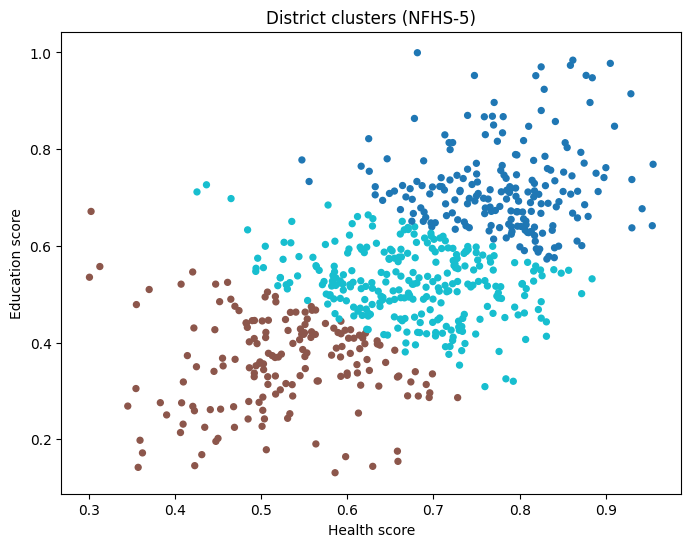

In [18]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

feat = ["health_score", "education_score"]
Xc = norm[feat]

# 1. Try 3, 4 and 5 clusters and pick the best by silhouette score
sil = {}
for k in range(3, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xc)
    sil[k] = silhouette_score(Xc, km.labels_)
    print("k =", k, "-> silhouette", round(sil[k], 3))
best_k = max(sil, key=sil.get)
print("Chosen k:", best_k)

km = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xc)
norm["cluster"] = km.labels_

# 2. Profile each cluster
prof = norm.groupby("cluster").agg(
    districts=("District Name", "count"),
    health=("health_score", "mean"),
    education=("education_score", "mean"),
    index=("dev_index", "mean")).round(2)
display(prof)

for c in sorted(norm["cluster"].unique()):
    sub = norm[norm["cluster"] == c]
    print(f"\nCluster {c}: main states ->", sub["State"].value_counts().head(3).to_dict())
    print("   lowest-scoring examples:", sub.sort_values("dev_index")["District Name"].head(3).tolist())

# 3. Plot and save
plt.figure(figsize=(8, 6))
plt.scatter(norm["health_score"], norm["education_score"], c=norm["cluster"], cmap="tab10", s=18)
plt.xlabel("Health score")
plt.ylabel("Education score")
plt.title("District clusters (NFHS-5)")
plt.savefig(f"{base}/dashboard/clusters.png", dpi=150, bbox_inches="tight")
plt.show()

norm.to_csv(f"{base}/data/clean/district_clusters.csv", index=False)

In [19]:
# Name the clusters by their average index (so labels stay correct if ids change)
order = norm.groupby("cluster")["dev_index"].mean().sort_values().index.tolist()
labels = dict(zip(order, ["Priority: weak on both", "Middle", "Higher-performing"]))
norm["group"] = norm["cluster"].map(labels)

# Gap = health score minus education score
norm["gap"] = norm["health_score"] - norm["education_score"]

show2 = ["State", "District Name", "health_score", "education_score", "gap", "group"]
print("EDUCATION LAGS HEALTH THE MOST (priority: schooling and literacy)")
display(norm.sort_values("gap", ascending=False)[show2].head(10).round(2))

print("HEALTH LAGS EDUCATION THE MOST (priority: health services)")
display(norm.sort_values("gap")[show2].head(10).round(2))

# Share of districts in the Priority group, by state (states with 10+ districts)
st = norm.groupby("State").agg(
    districts=("District Name", "count"),
    priority=("group", lambda s: (s == "Priority: weak on both").sum()),
    avg_index=("dev_index", "mean"))
st["priority_share_%"] = (st["priority"] / st["districts"] * 100).round(0)
print("\nSTATES WITH THE HIGHEST SHARE OF PRIORITY DISTRICTS")
display(st[st["districts"] >= 10].sort_values("priority_share_%", ascending=False).head(10).round(1))

norm.to_csv(f"{base}/data/clean/district_final.csv", index=False)
print(norm["group"].value_counts())

EDUCATION LAGS HEALTH THE MOST (priority: schooling and literacy)


,State,District Name,health_score,education_score,gap,group
272,Madhya Pradesh,Alirajpur,0.66,0.15,0.50,Priority: weak on both
422,Odisha,Malkangiri,0.63,0.14,0.49,Priority: weak on both
421,Odisha,Koraput,0.66,0.18,0.48,Priority: weak on both
462,Rajasthan,Bhilwara,0.79,0.32,0.47,Middle
313,Madhya Pradesh,Shajapur,0.78,0.32,0.46,Middle
294,Madhya Pradesh,Jhabua,0.59,0.13,0.46,Priority: weak on both
465,Rajasthan,Chittaurgarh,0.76,0.31,0.45,Middle
288,Madhya Pradesh,Guna,0.73,0.29,0.44,Priority: weak on both
424,Odisha,Nabarangapur,0.60,0.16,0.43,Priority: weak on both
187,Jammu & Kashmir,Ganderbal,0.83,0.41,0.42,Middle


HEALTH LAGS EDUCATION THE MOST (priority: health services)


,State,District Name,health_score,education_score,gap,group
401,Nagaland,Zunheboto,0.30,0.67,-0.37,Priority: weak on both
433,Puducherry,Mahe,0.68,1.00,-0.32,Higher-performing
368,Meghalaya,East Khasi Hills,0.44,0.73,-0.29,Middle
400,Nagaland,Wokha,0.43,0.71,-0.29,Middle
373,Meghalaya,West Khasi Hills,0.31,0.56,-0.24,Priority: weak on both
399,Nagaland,Tuensang,0.30,0.54,-0.23,Priority: weak on both
365,Manipur,Ukhrul,0.47,0.70,-0.23,Middle
380,Mizoram,Saiha,0.55,0.78,-0.23,Higher-performing
255,Kerala,Alappuzha,0.75,0.95,-0.20,Higher-performing
264,Kerala,Palakkad,0.62,0.82,-0.20,Higher-performing



STATES WITH THE HIGHEST SHARE OF PRIORITY DISTRICTS


,districts,priority,avg_index,priority_share_%
State,,,,
Bihar,38,33,43.1,87.0
Jharkhand,23,16,45.8,70.0
Madhya Pradesh,50,23,53.2,46.0
Uttar Pradesh,71,33,51.9,46.0
Nagaland,11,5,55.1,45.0
Rajasthan,33,12,55.7,36.0
Gujarat,26,7,56.4,27.0
Telangana,11,3,58.2,27.0
Odisha,30,7,60.2,23.0


group
Middle                    278
Higher-performing         197
Priority: weak on both    167
Name: count, dtype: int64


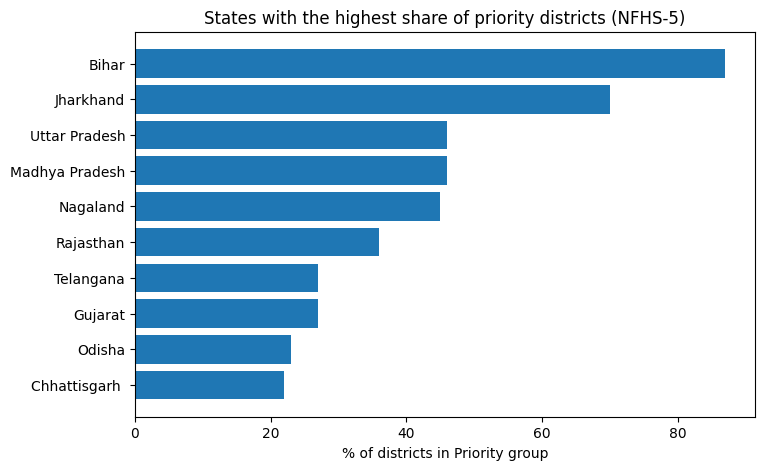

In [20]:
import matplotlib.pyplot as plt
top = st[st["districts"] >= 10].sort_values("priority_share_%").tail(10)
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["priority_share_%"])
plt.xlabel("% of districts in Priority group")
plt.title("States with the highest share of priority districts (NFHS-5)")
plt.savefig(f"{base}/dashboard/priority_by_state.png", dpi=150, bbox_inches="tight")
plt.show()